In [63]:
%run libs.py

In [64]:
from pathlib import Path

In [65]:
sns.set_theme(style="whitegrid")

pd.set_option("display.max_columns", None)
pd.set_option("display.width", None)

In [66]:
RESULTS_DIR = Path("results")

csv_files = sorted(
    RESULTS_DIR.glob("*.csv")
)

print(
    f"Found {len(csv_files)} result files"
)

all_results = []

for file in csv_files:

    df = pd.read_csv(file)

    print(
        f"{file.stem:<20}"
        f"rows={len(df)}"
    )

    all_results.append(df)

results_df = pd.concat(
    all_results,
    ignore_index=True
)

print()
print(results_df.shape)

results_df.head()

Found 8 result files
chronos             rows=6
control_naive       rows=132
control_snaive      rows=27
lightgbm            rows=99
lstm                rows=8
sarima              rows=9
ttm1                rows=66
xgboost             rows=55

(402, 12)


,model,n_series,n_rows,horizon,runtime_seconds,MAE,RMSE,SMAPE,dataset,horizon_type,season_length,max_series
0,Chronos,128,7791,1,16.775607,126485.937559,126485.937559,5.248247,std_agri_medium,short,NaN,NaN
1,Chronos,128,7791,3,27.416173,171924.844856,192344.644624,7.104235,std_agri_medium,medium,NaN,NaN
2,Chronos,128,7791,5,41.593312,263027.398775,292291.278800,10.277496,std_agri_medium,long,NaN,NaN
3,Chronos,27,1560,1,4.093183,74762.478840,74762.478840,3.735279,std_agri_small,short,NaN,NaN
4,Chronos,27,1560,3,5.926446,175341.301647,195637.138460,8.747329,std_agri_small,medium,NaN,NaN


In [67]:
print(
    "Total Rows:",
    len(results_df)
)

print()

print(
    "Duplicate Rows:",
    results_df.duplicated().sum()
)

print()

display(
    results_df.isna().sum()
)

results_df = (
    results_df
    .drop_duplicates()
    .reset_index(drop=True)
)

print(results_df.shape)

Total Rows: 402

Duplicate Rows: 35



model                0
n_series             0
n_rows               0
horizon              0
runtime_seconds      0
MAE                  0
RMSE                 0
SMAPE                0
dataset              0
horizon_type         0
season_length      366
max_series         393
dtype: int64

(367, 12)


In [68]:
def dataset_size(dataset):

    dataset = str(dataset).lower()

    if "small" in dataset:
        return "Small"

    if "medium" in dataset:
        return "Medium"

    if "large" in dataset:
        return "Large"

    return "Unknown"


results_df["dataset_size"] = (
    results_df["dataset"]
    .apply(dataset_size)
)

In [69]:
FOUNDATION_MODELS = [
    "Chronos",
    "LagLlama",
    "Moirai",
    "TTM-1"
]

TRADITIONAL_MODELS = [
    "Naive",
    "SeasonalNaive",
    "ARIMA",
    "SARIMA",
    "Prophet"
]

ML_MODELS = [
    "XGBoost",
    "LightGBM",
]

DEEP_LEARNING_MODELS = [
    "LSTM",
    "NHiTS"
]


def classify_model(model):

    if model in FOUNDATION_MODELS:
        return "Foundation"

    if model in TRADITIONAL_MODELS:
        return "Traditional"

    if model in ML_MODELS:
        return "Machine Learning"

    if model in DEEP_LEARNING_MODELS:
        return "Deep Learning"

    return "Other"


results_df["model_family"] = (
    results_df["model"]
    .apply(classify_model)
)

In [70]:
def classify_model(model):

    if model in FOUNDATION_MODELS:
        return "Foundation"

    if model in TRADITIONAL_MODELS:
        return "Traditional"

    if model in ML_MODELS:
        return "Machine Learning"

    if model in DEEP_LEARNING_MODELS:
        return "Deep Learning"

    return "Other"


results_df["model_family"] = (
    results_df["model"]
    .apply(classify_model)
)

results_df.head()

,model,n_series,n_rows,horizon,runtime_seconds,MAE,RMSE,SMAPE,dataset,horizon_type,season_length,max_series,dataset_size,model_family
0,Chronos,128,7791,1,16.775607,126485.937559,126485.937559,5.248247,std_agri_medium,short,NaN,NaN,Medium,Foundation
1,Chronos,128,7791,3,27.416173,171924.844856,192344.644624,7.104235,std_agri_medium,medium,NaN,NaN,Medium,Foundation
2,Chronos,128,7791,5,41.593312,263027.398775,292291.278800,10.277496,std_agri_medium,long,NaN,NaN,Medium,Foundation
3,Chronos,27,1560,1,4.093183,74762.478840,74762.478840,3.735279,std_agri_small,short,NaN,NaN,Small,Foundation
4,Chronos,27,1560,3,5.926446,175341.301647,195637.138460,8.747329,std_agri_small,medium,NaN,NaN,Small,Foundation


In [71]:
results_df.to_csv("HI.csv")

In [72]:
print(
    "Datasets:",
    results_df["dataset"].nunique()
)

print(
    "Models:",
    results_df["model"].nunique()
)

print()

display(
    results_df.groupby("model")
    .size()
    .sort_values(ascending=False)
)

Datasets: 33
Models: 8



model
LightGBM         99
Naive            99
TTM-1            66
XGBoost          55
SeasonalNaive    27
SARIMA            9
Chronos           6
LSTM              6
dtype: int64

In [73]:
naive = (
    results_df[
        results_df["model"] == "Naive"
    ]
    [
        [
            "dataset",
            "horizon_type",
            "SMAPE"
        ]
    ]
    .rename(
        columns={
            "SMAPE":"naive_smape"
        }
    )
)

comparison_df = results_df.merge(
    naive,
    on=[
        "dataset",
        "horizon_type"
    ]
)

comparison_df[
    "improvement_vs_naive"
] = (
    (
        comparison_df["naive_smape"]
        -
        comparison_df["SMAPE"]
    )
    /
    comparison_df["naive_smape"]
) * 100

In [74]:
foundation_vs_naive = (
    comparison_df[
        comparison_df["model_family"]
        == "Foundation"
    ]
    .groupby("model")
    [
        "improvement_vs_naive"
    ]
    .mean()
    .sort_values(
        ascending=False
    )
)

foundation_vs_naive

model
Chronos     -1.473343
TTM-1     -337.956476
Name: improvement_vs_naive, dtype: float64

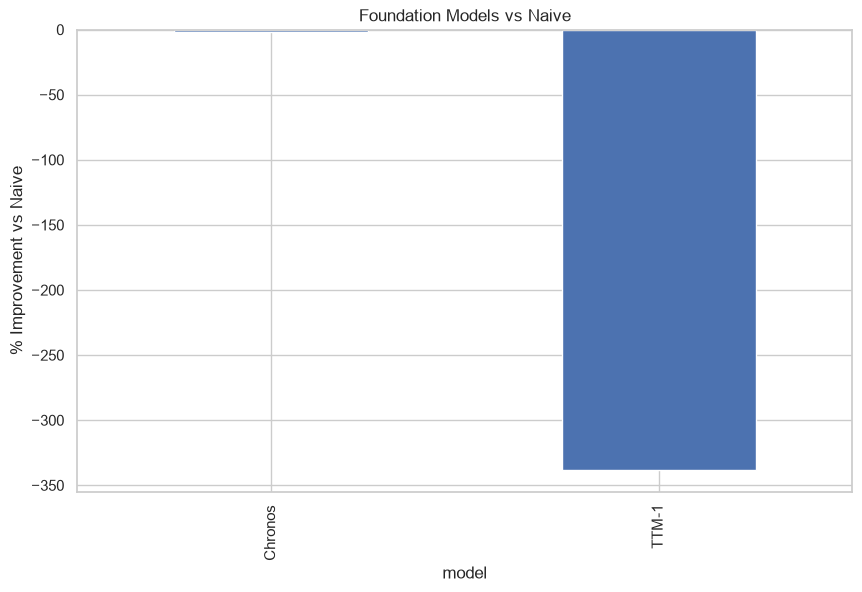

In [75]:
plt.figure(figsize=(10,6))

foundation_vs_naive.plot(
    kind="bar"
)

plt.ylabel(
    "% Improvement vs Naive"
)

plt.title(
    "Foundation Models vs Naive"
)

plt.show()

In [76]:
family_summary = (
    results_df
    .groupby("model_family")
    .agg(
        mean_smape=("SMAPE","mean"),    
        mean_rmse=("RMSE","mean"),
        mean_runtime=("runtime_seconds","mean")
    )
    .sort_values("mean_smape")
)

family_summary

,mean_smape,mean_rmse,mean_runtime
model_family,,,
Machine Learning,20.883254,8.383261e+04,321.232360
Traditional,24.371825,1.462413e+61,6.277926
Foundation,43.104053,1.953898e+05,70.026632
Deep Learning,194.983193,2.660879e+06,173.316325


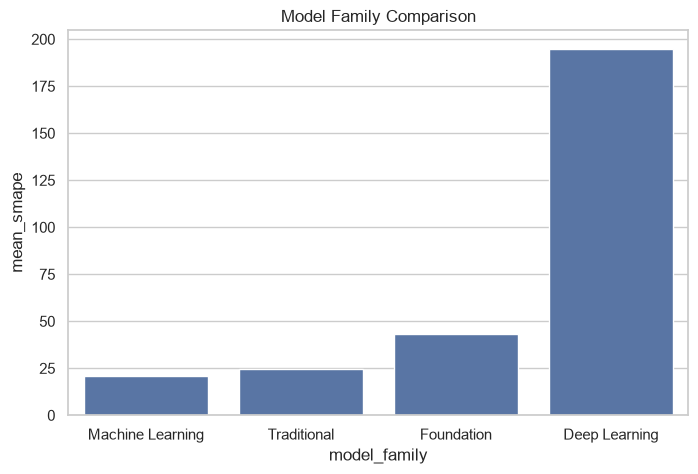

In [77]:
plt.figure(figsize=(8,5))

sns.barplot(
    data=family_summary.reset_index(),
    x="model_family",
    y="mean_smape"
)

plt.title(
    "Model Family Comparison"
)

plt.show()

In [78]:
foundation_leaderboard = (
    results_df[
        results_df["model_family"]
        == "Foundation"
    ]
    .groupby("model")
    .agg(
        mean_smape=("SMAPE","mean"),
        mean_rmse=("RMSE","mean"),
        mean_runtime=("runtime_seconds","mean")
    )
    .sort_values("mean_smape")
)

foundation_leaderboard

,mean_smape,mean_rmse,mean_runtime
model,,,
Chronos,8.145214,219695.026831,17.435887
TTM-1,46.282129,193180.266028,74.807608


In [79]:
foundation_df = (
    results_df[
        results_df["model_family"]
        == "Foundation"
    ]
)

winners = (
    foundation_df
    .sort_values("SMAPE")
    .groupby(
        [
            "dataset",
            "horizon_type"
        ]
    )
    .first()
)

win_counts = (
    winners["model"]
    .value_counts()
)

win_counts

model
TTM-1      60
Chronos     6
Name: count, dtype: int64

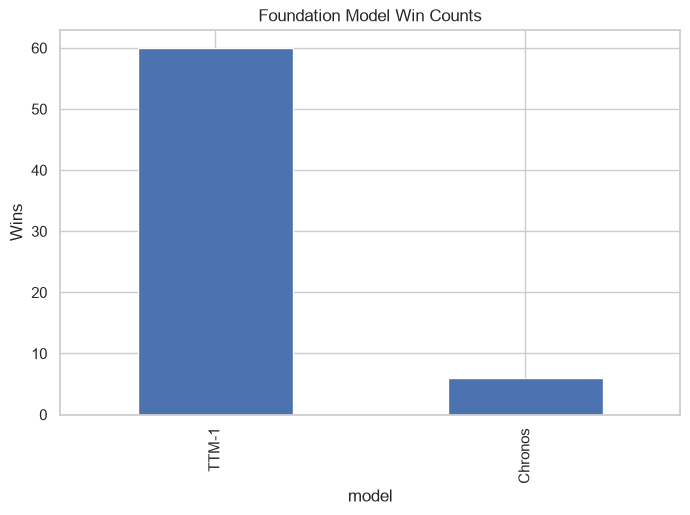

In [80]:
plt.figure(figsize=(8,5))

win_counts.plot(
    kind="bar"
)

plt.ylabel("Wins")

plt.title(
    "Foundation Model Win Counts"
)

plt.show()

In [81]:
horizon_summary = (
    results_df
    .groupby(
        [
            "model_family",
            "horizon_type"
        ]
    )
    ["SMAPE"]
    .mean()
    .reset_index()
)

horizon_summary

,model_family,horizon_type,SMAPE
0,Deep Learning,long,185.000297
1,Deep Learning,medium,199.980042
2,Deep Learning,short,199.969239
3,Foundation,long,43.687728
4,Foundation,medium,42.728362
5,Foundation,short,42.896070
6,Machine Learning,long,24.242588
7,Machine Learning,medium,20.066326
8,Machine Learning,short,18.389742
9,Traditional,long,31.214249


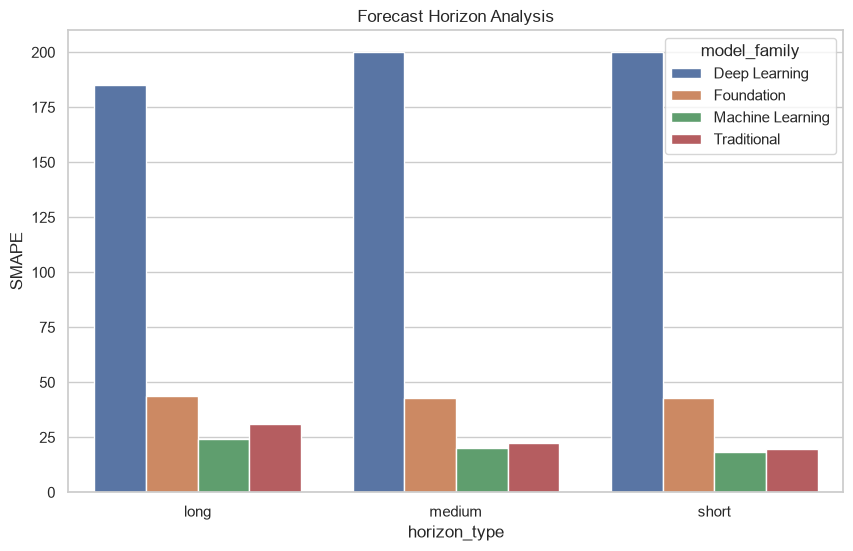

In [82]:
plt.figure(figsize=(10,6))

sns.barplot(
    data=horizon_summary,
    x="horizon_type",
    y="SMAPE",
    hue="model_family"
)

plt.title(
    "Forecast Horizon Analysis"
)

plt.show()

In [83]:
size_summary = (
    results_df
    .groupby(
        [
            "model_family",
            "dataset_size"
        ]
    )
    ["SMAPE"]
    .mean()
    .reset_index()
)

size_summary

,model_family,dataset_size,SMAPE
0,Deep Learning,Medium,197.056847
1,Deep Learning,Small,192.909538
2,Foundation,Medium,45.148885
3,Foundation,Small,41.059221
4,Machine Learning,Large,21.472537
5,Machine Learning,Medium,20.839516
6,Machine Learning,Small,20.326155
7,Traditional,Large,25.173489
8,Traditional,Medium,22.611948
9,Traditional,Small,25.330036


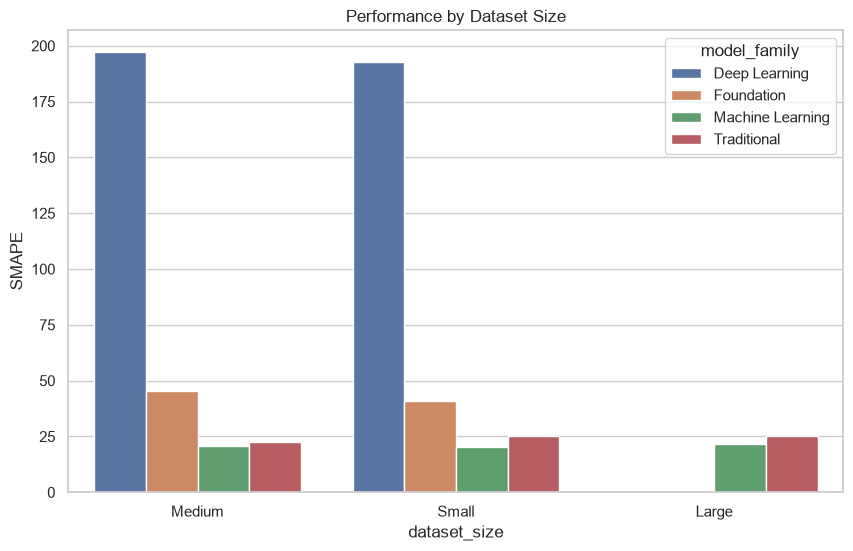

In [84]:
plt.figure(figsize=(10,6))

sns.barplot(
    data=size_summary,
    x="dataset_size",
    y="SMAPE",
    hue="model_family"
)

plt.title(
    "Performance by Dataset Size"
)

plt.show()

In [85]:
runtime_summary = (
    results_df
    .groupby("model_family")
    .agg(
        smape=("SMAPE","mean"),
        runtime=("runtime_seconds","mean")
    )
    .reset_index()
)

runtime_summary

,model_family,smape,runtime
0,Deep Learning,194.983193,173.316325
1,Foundation,43.104053,70.026632
2,Machine Learning,20.883254,321.232360
3,Traditional,24.371825,6.277926


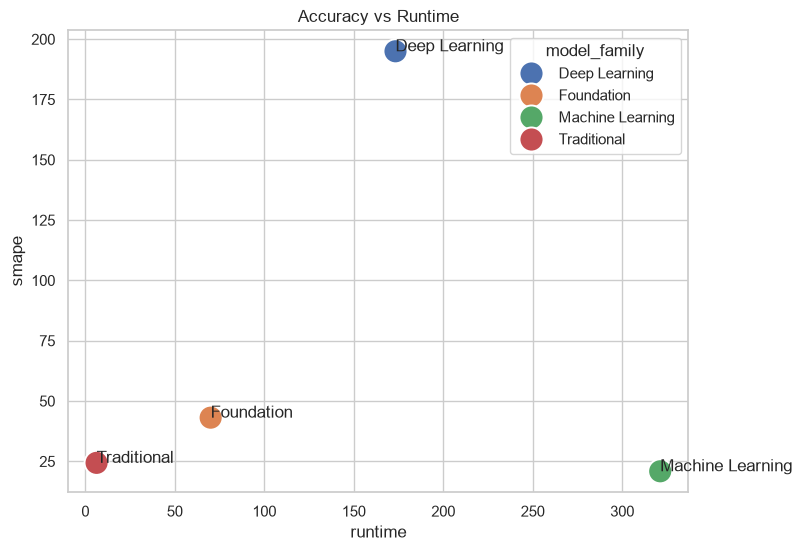

In [86]:
plt.figure(figsize=(8,6))

sns.scatterplot(
    data=runtime_summary,
    x="runtime",
    y="smape",
    hue="model_family",
    s=300
)

for _, row in runtime_summary.iterrows():

    plt.text(
        row["runtime"],
        row["smape"],
        row["model_family"]
    )

plt.title(
    "Accuracy vs Runtime"
)

plt.show()

In [87]:
foundation_df = (
    results_df[
        results_df["model_family"]
        == "Foundation"
    ]
)

pivot = foundation_df.pivot_table(
    index=[
        "dataset",
        "horizon_type"
    ],
    columns="model",
    values="SMAPE"
)

models = list(
    pivot.columns
)

win_matrix = pd.DataFrame(
    index=models,
    columns=models,
    dtype=float
)

for m1 in models:

    for m2 in models:

        if m1 == m2:

            win_matrix.loc[m1,m2] = np.nan

        else:

            wins = (
                pivot[m1]
                <
                pivot[m2]
            ).sum()

            win_matrix.loc[m1,m2] = wins

win_matrix

,Chronos,TTM-1
Chronos,NaN,6.0
TTM-1,0.0,NaN


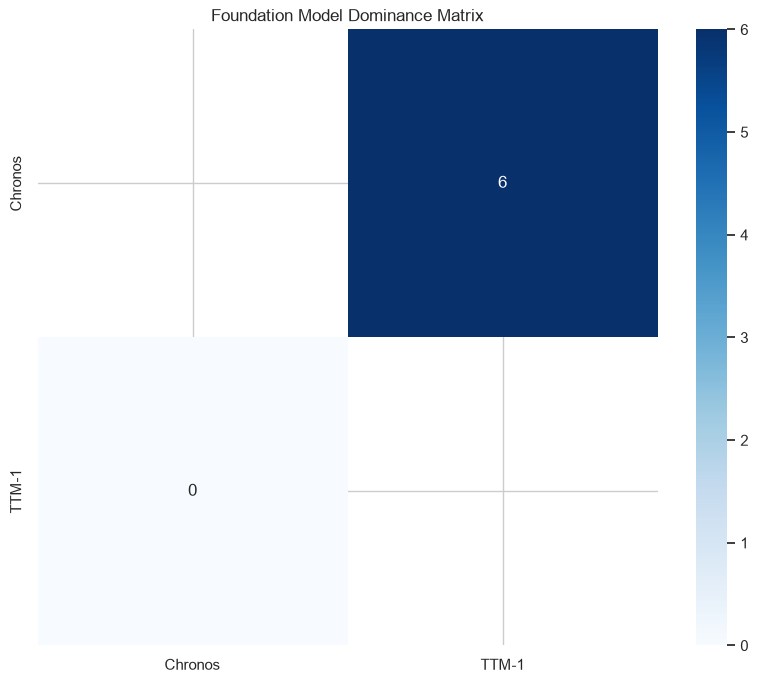

In [88]:
plt.figure(figsize=(10,8))

sns.heatmap(
    win_matrix,
    annot=True,
    fmt=".0f",
    cmap="Blues"
)

plt.title(
    "Foundation Model Dominance Matrix"
)

plt.show()

In [89]:
display(
    foundation_leaderboard
)

display(
    family_summary
)

display(
    foundation_vs_naive
)

display(
    win_counts
)

,mean_smape,mean_rmse,mean_runtime
model,,,
Chronos,8.145214,219695.026831,17.435887
TTM-1,46.282129,193180.266028,74.807608


,mean_smape,mean_rmse,mean_runtime
model_family,,,
Machine Learning,20.883254,8.383261e+04,321.232360
Traditional,24.371825,1.462413e+61,6.277926
Foundation,43.104053,1.953898e+05,70.026632
Deep Learning,194.983193,2.660879e+06,173.316325


model
Chronos     -1.473343
TTM-1     -337.956476
Name: improvement_vs_naive, dtype: float64

model
TTM-1      60
Chronos     6
Name: count, dtype: int64